In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("aqi.csv", parse_dates=["date"])
print("Shape:", df.shape)
df.head()

Shape: (90, 4)


,date,pm25,pm10,co
0,2026-01-01,81.264043,121.701105,1.288901
1,2026-01-02,92.498783,126.602617,1.621440
2,2026-01-03,55.102277,127.325972,0.946457
3,2026-01-04,97.339963,106.894428,1.051759
4,2026-01-05,69.542462,153.414451,1.014582


In [3]:
df.info()
print()
print("Missing values:", df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    90 non-null     datetime64[us]
 1   pm25    90 non-null     float64       
 2   pm10    90 non-null     float64       
 3   co      90 non-null     float64       
dtypes: datetime64[us](1), float64(3)
memory usage: 2.9 KB

Missing values: 0


In [4]:
df["aqi"] = (df["pm25"] * 1.2 + df["pm10"] * 0.5).astype(int)
print("AQI minimum:", df["aqi"].min())
print("AQI maximum:", df["aqi"].max())
print(df.describe())

AQI minimum: 63
AQI maximum: 232
                      date        pm25        pm10         co         aqi
count                   90   90.000000   90.000000  90.000000   90.000000
mean   2026-02-14 12:00:00   80.918911  122.458523   1.221775  157.844444
min    2026-01-01 00:00:00   20.505618   51.189485   0.411299   63.000000
25%    2026-01-23 06:00:00   63.741348  103.431085   1.007870  135.000000
50%    2026-02-14 12:00:00   81.312431  121.526669   1.142707  156.500000
75%    2026-03-08 18:00:00   96.871658  143.381380   1.503508  179.000000
max    2026-03-31 00:00:00  141.914604  197.124741   2.074339  232.000000
std                    NaN   25.418651   32.207356   0.388954   33.402520


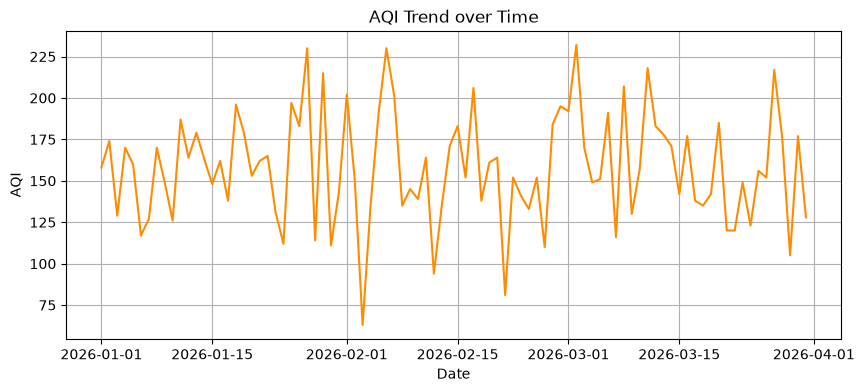

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(df["date"], df["aqi"], color="darkorange")
plt.title("AQI Trend over Time")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.grid(True)
plt.show()

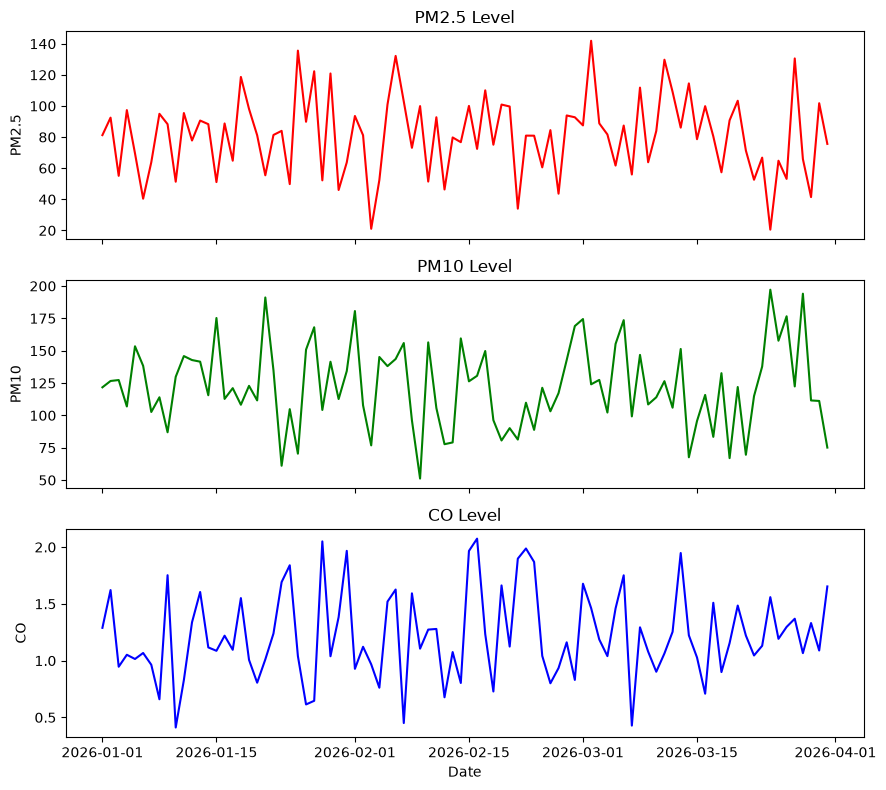

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
ax[0].plot(df["date"], df["pm25"], color="red")
ax[0].set_title("PM2.5 Level")
ax[0].set_ylabel("PM2.5")
ax[1].plot(df["date"], df["pm10"], color="green")
ax[1].set_title("PM10 Level")
ax[1].set_ylabel("PM10")
ax[2].plot(df["date"], df["co"], color="blue")
ax[2].set_title("CO Level")
ax[2].set_ylabel("CO")
ax[2].set_xlabel("Date")
plt.tight_layout()
plt.show()

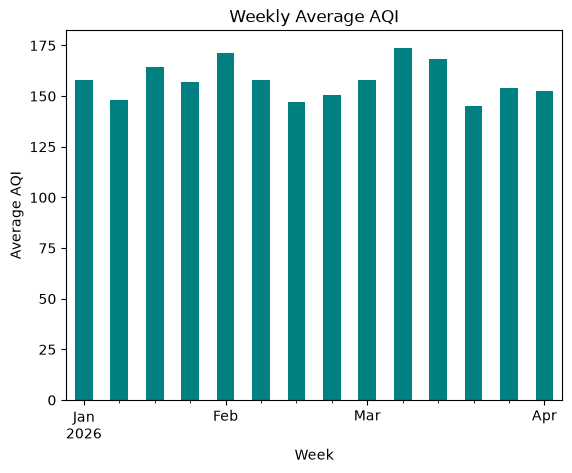

In [7]:
weekly = df.set_index("date")["aqi"].resample("W").mean()
weekly.plot(kind="bar", color="teal")
plt.title("Weekly Average AQI")
plt.xlabel("Week")
plt.ylabel("Average AQI")
plt.show()

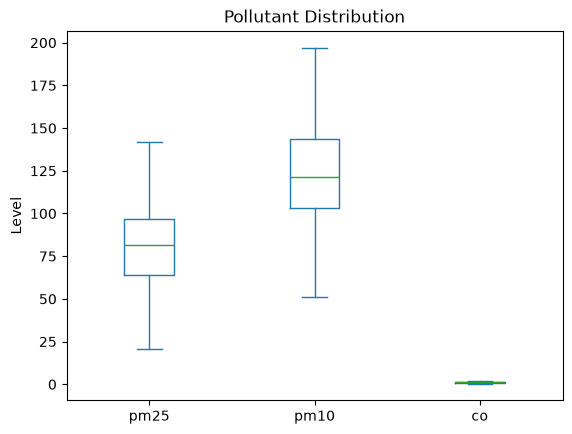

In [8]:
df[["pm25", "pm10", "co"]].plot(kind="box")
plt.title("Pollutant Distribution")
plt.ylabel("Level")
plt.show()

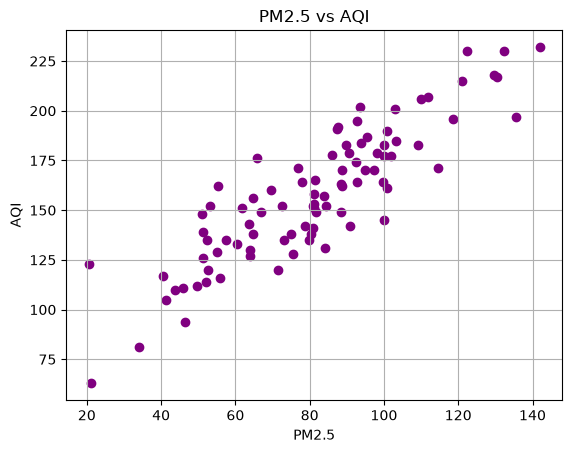

In [9]:
plt.scatter(df["pm25"], df["aqi"], color="purple")
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.grid(True)
plt.show()